# Character-count emergence and layer-1 MLP accumulation

This notebook measures count decodability at four sites around layer 1 and performs causal token-length swaps. It uses identical train/evaluation splits for every site.

In [1]:
from pathlib import Path
import sys, json
import numpy as np, pandas as pd, torch
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, r2_score, accuracy_score

ROOT = next(p for p in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent, Path.cwd().parent.parent.parent] if (p / "results/line_breaks_results").exists())
sys.path.insert(0, str(ROOT / "src"))
import project_main.checkpoints as checkpoints
import project_main.data as data
import project_main.model as model_lib
import project_main.tokens as tokens_lib

TRAIN_SEED, EVAL_SEED = 8011, 8012
N_TRAIN = N_EVAL = 256
BATCH_SIZE = 32
SITES = ["blocks.1.hook_resid_pre", "blocks.1.hook_resid_mid", "blocks.1.hook_mlp_out", "blocks.1.hook_resid_post"]
short = dict(zip(SITES, ["pre layer 1", "pre MLP", "MLP output", "post layer 1"]))
cfg = json.loads((ROOT / "results/line_breaks_results/config.json").read_text())
device = "cuda" if torch.cuda.is_available() else "cpu"
vocab = tokens_lib.build_vocab(cfg["task"])
model = model_lib.build_model(cfg=cfg, device=device)
checkpoint = checkpoints.load_checkpoint(path=ROOT / "results/line_breaks_results/checkpoints/final.pt", model=model, map_location=device)
model.eval()

def collect(n, seed):
    toks, acts, labs = [], {s: [] for s in SITES}, []
    for start in range(0, n, BATCH_SIZE):
        size = min(BATCH_SIZE, n - start)
        batch = data.make_batch(size, vocab, cfg["task"], device, seed + start)
        with torch.no_grad():
            _, cache = model.run_with_cache(batch.tokens, prepend_bos=False, names_filter=SITES)
        t = batch.tokens.detach().cpu().numpy(); toks.append(t)
        for s in SITES: acts[s].append(cache[s].detach().cpu().numpy())
        y = np.zeros(t.shape, dtype=np.int64)
        for b, row in enumerate(t):
            count = 0
            for p, token_id in enumerate(row):
                name = vocab.decode_token(int(token_id))
                if name in {"BOS", "_NEWLINE_"}: count = 0
                else:
                    count += data.extract_character_count(name); y[b, p] = count
        labs.append(y)
    return np.concatenate(toks), {s: np.concatenate(acts[s]) for s in SITES}, np.concatenate(labs)

train_tokens, train_acts, train_y = collect(N_TRAIN, TRAIN_SEED)
eval_tokens, eval_acts, eval_y = collect(N_EVAL, EVAL_SEED)
train_masks = {s: train_y.ravel() > 0 for s in SITES}
eval_masks = {s: eval_y.ravel() > 0 for s in SITES}
print("checkpoint", checkpoint["step"], "device", device)
print("train/eval examples", len(train_tokens), len(eval_tokens), "count classes", int(train_y.max()))


Building vocab...
('BOS', '_NEWLINE_')


checkpoint 10000 device cpu
train/eval examples 256 256 count classes 106


## Matched count probes

The ridge probe measures continuous count information; the multinomial probe measures exact count-class accuracy. BOS and newline positions are excluded.

In [2]:
probe_rows, count_models = [], {}
for site in SITES:
    Xtr = train_acts[site].reshape(-1, 128)[train_masks[site]]; ytr = train_y.ravel()[train_masks[site]]
    Xev = eval_acts[site].reshape(-1, 128)[eval_masks[site]]; yev = eval_y.ravel()[eval_masks[site]]
    ridge = make_pipeline(StandardScaler(), Ridge(alpha=10.0)).fit(Xtr, ytr)
    pred = ridge.predict(Xev); rounded = np.clip(np.rint(pred), yev.min(), yev.max()).astype(int)
    clf = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1000, solver="lbfgs")).fit(Xtr, ytr)
    exact = clf.predict(Xev)
    probe_rows.append({"site": site, "n_eval": len(yev), "R2": r2_score(yev, pred), "MAE": mean_absolute_error(yev, pred), "rounded_accuracy": accuracy_score(yev, rounded), "exact_accuracy": accuracy_score(yev, exact)})
    count_models[site] = ridge
probe_results = pd.DataFrame(probe_rows)
display(probe_results.round(4))


,site,n_eval,R2,MAE,rounded_accuracy,exact_accuracy
0,blocks.1.hook_resid_pre,36121,0.4808,13.9864,0.0270,0.0646
1,blocks.1.hook_resid_mid,36121,0.9792,2.7274,0.1233,0.2404
2,blocks.1.hook_mlp_out,36121,0.9976,0.8979,0.3705,0.2773
3,blocks.1.hook_resid_post,36121,0.9970,0.9941,0.3360,0.2787


## Causal token-length swaps

At a middle-segment content position, replace the current token with a token of a different length while leaving the other input tokens fixed. The immediate count changes by exactly the length difference.


In [3]:
ids_by_length = {}
for token_id in range(vocab.size):
    name = vocab.decode_token(token_id)
    if name not in {"BOS", "_NEWLINE_"}:
        ids_by_length.setdefault(data.extract_character_count(name), []).append(token_id)

def count_at(row, p):
    count = 0
    for token_id in row[:p + 1]:
        name = vocab.decode_token(int(token_id))
        count = 0 if name == "_NEWLINE_" else count + data.extract_character_count(name)
    return count

def target_position(row):
    nls = [i for i, token_id in enumerate(row) if int(token_id) == vocab.newline_id]
    if len(nls) < 2:
        return None
    candidates = [p for p in range(nls[0] + 1, nls[1]) if int(row[p]) != vocab.newline_id]
    return candidates[len(candidates) // 2] if len(candidates) >= 5 else None

post_model = count_models["blocks.1.hook_resid_post"]
scaler = post_model.named_steps["standardscaler"]
ridge = post_model.named_steps["ridge"]
count_direction = ridge.coef_ / scaler.scale_; rng = np.random.default_rng(8014)
swap_rows = []
for sample in range(128):
    batch = data.make_batch(1, vocab, cfg["task"], device, 8013 + sample)
    clean = batch.tokens.detach().cpu().numpy()[0]
    p = target_position(clean)
    if p is None:
        continue
    old_id = int(clean[p])
    old_len = data.extract_character_count(vocab.decode_token(old_id))
    new_len = int(rng.choice([x for x in ids_by_length if x != old_len]))
    counter = clean.copy(); counter[p] = int(rng.choice(ids_by_length[new_len]))
    counter_batch = batch.tokens.clone(); counter_batch[0] = torch.as_tensor(counter, device=device)
    with torch.no_grad():
        _, c0 = model.run_with_cache(batch.tokens, prepend_bos=False, names_filter=SITES)
        _, c1 = model.run_with_cache(counter_batch, prepend_bos=False, names_filter=SITES)
    for site in SITES:
        v0 = c0[site][0, p].detach().cpu().numpy(); v1 = c1[site][0, p].detach().cpu().numpy()
        swap_rows.append({"sample": sample, "site": site, "delta_length": new_len - old_len, "delta_count": count_at(counter, p) - count_at(clean, p), "delta_coordinate": float((v1 - v0) @ count_direction)})
swap_results = pd.DataFrame(swap_rows); swap_summary = []
for site, group in swap_results.groupby("site"):
    fit = Ridge(alpha=1e-6).fit(group[["delta_length"]], group["delta_coordinate"])
    swap_summary.append({"site": site, "n_swaps": len(group), "correlation": np.corrcoef(group.delta_length, group.delta_coordinate)[0, 1], "slope": fit.coef_[0], "R2": fit.score(group[["delta_length"]], group.delta_coordinate)})
print("Swap changes projected onto the post-layer-1 count direction")
display(pd.DataFrame(swap_summary).round(4))


Swap changes projected onto the post-layer-1 count direction


,site,n_swaps,correlation,slope,R2
0,blocks.1.hook_mlp_out,128,-0.8695,-0.2683,0.7560
1,blocks.1.hook_resid_mid,128,0.9859,1.3799,0.9719
2,blocks.1.hook_resid_post,128,0.9843,1.1115,0.9688
3,blocks.1.hook_resid_pre,128,0.9589,0.7271,0.9195


## Figures


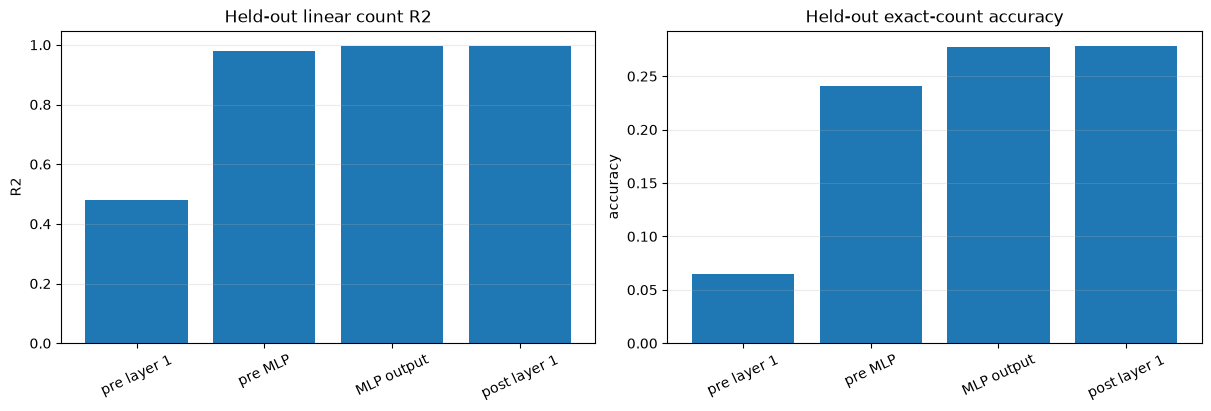

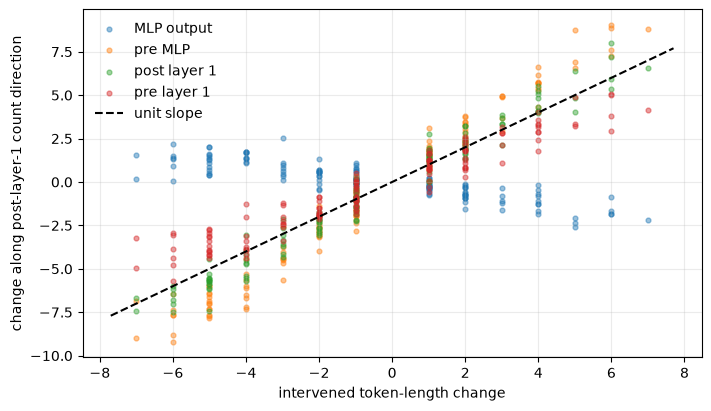

In [4]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
table = probe_results.copy(); table["label"] = table.site.map(short)
axes[0].bar(table.label, table.R2); axes[0].set_title("Held-out linear count R2"); axes[0].set_ylabel("R2")
axes[1].bar(table.label, table.exact_accuracy); axes[1].set_title("Held-out exact-count accuracy"); axes[1].set_ylabel("accuracy")
for ax in axes:
    ax.tick_params(axis="x", rotation=25); ax.grid(axis="y", alpha=.25)
plt.show()
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
for site, group in swap_results.groupby("site"):
    ax.scatter(group.delta_length, group.delta_coordinate, s=12, alpha=.45, label=short[site])
lo, hi = ax.get_xlim(); ax.plot([lo, hi], [lo, hi], "k--", label="unit slope")
ax.set_xlabel("intervened token-length change"); ax.set_ylabel("change along post-layer-1 count direction")
ax.legend(frameon=False); ax.grid(alpha=.25); plt.show()
